# Real codec time and rate-distortion summary

统一展示 Landsat8 与 RS 的真实 `compress()` / `decompress()` 时间、BPP、PSNR 和 MS-SSIM(dB)。计时在调用前后执行 CUDA 同步；每种方法使用相同的前 5 张图、1 张预热图。HL 结果来自适配器，因此不进入本表和图。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.style.use('seaborn-v0_8-whitegrid')
csv_path = Path('并行优化/codec_time_comparison.csv')
if not csv_path.exists():
    csv_path = Path('codec_time_comparison.csv')
raw = pd.read_csv(csv_path)
data = raw.loc[raw['method'] != 'hl_adapter'].copy()
labels = {
    'hpcm': 'HPCM', 'mlic': 'MLIC', 'elic': 'ELIC', 'rwk': 'RWK',
    'ftic': 'FTIC', 'mamba_serial': 'Mamba serial',
    'hybrid_python_serial': 'Hybrid Python',
    'hybrid_native_1w': 'Hybrid native 1T',
    'hybrid_native_4w': 'Hybrid native 4T',
}
data['display_method'] = data['method'].map(labels)
data['total_codec_s'] = data['compress_mean_s'] + data['decompress_mean_s']
data['codec_fps'] = 1.0 / data['total_codec_s']
data.shape

(18, 17)

## Complete numeric results

In [2]:
columns = [
    'dataset', 'display_method', 'compress_mean_s', 'decompress_mean_s',
    'total_codec_s', 'codec_fps', 'bpp', 'psnr', 'ms_ssim_db',
    'latent_exact', 'codec_type'
]
table = data[columns].sort_values(['dataset', 'total_codec_s']).reset_index(drop=True)
display(table.style.format({
    'compress_mean_s': '{:.4f}', 'decompress_mean_s': '{:.4f}',
    'total_codec_s': '{:.4f}', 'codec_fps': '{:.2f}',
    'bpp': '{:.4f}', 'psnr': '{:.3f}', 'ms_ssim_db': '{:.3f}',
}))

,dataset,display_method,compress_mean_s,decompress_mean_s,total_codec_s,codec_fps,bpp,psnr,ms_ssim_db,latent_exact,codec_type
0,landsat8,HPCM,0.0250,0.0235,0.0485,20.63,0.8123,42.583,21.640,not_checked,native
1,landsat8,FTIC,0.0461,0.0813,0.1275,7.85,0.4091,39.422,18.314,true,native_vectorized_rans
2,landsat8,Hybrid native 4T,0.0661,0.0661,0.1322,7.57,0.8043,41.894,21.085,true,native_rans_openmp_4w
3,landsat8,Hybrid native 1T,0.0664,0.0662,0.1326,7.54,0.8043,41.894,21.085,true,native_rans_openmp_1w
4,landsat8,MLIC,0.0861,0.1375,0.2236,4.47,0.6389,41.671,20.511,not_checked,native
5,landsat8,Hybrid Python,0.1106,0.1188,0.2295,4.36,0.8043,41.894,21.085,true,compressai_python
6,landsat8,ELIC,0.1517,0.0911,0.2428,4.12,0.8094,42.761,21.761,not_checked,native
7,landsat8,RWK,0.1549,0.0949,0.2498,4.00,0.8046,42.133,21.574,not_checked,native_torch112_historical_cuda
8,landsat8,Mamba serial,0.1880,0.1263,0.3143,3.18,0.7262,42.924,21.852,not_checked,native
9,rs,HPCM,0.0258,0.0243,0.0501,19.95,0.7845,54.644,30.916,not_checked,native


## Full codec time and quality plots

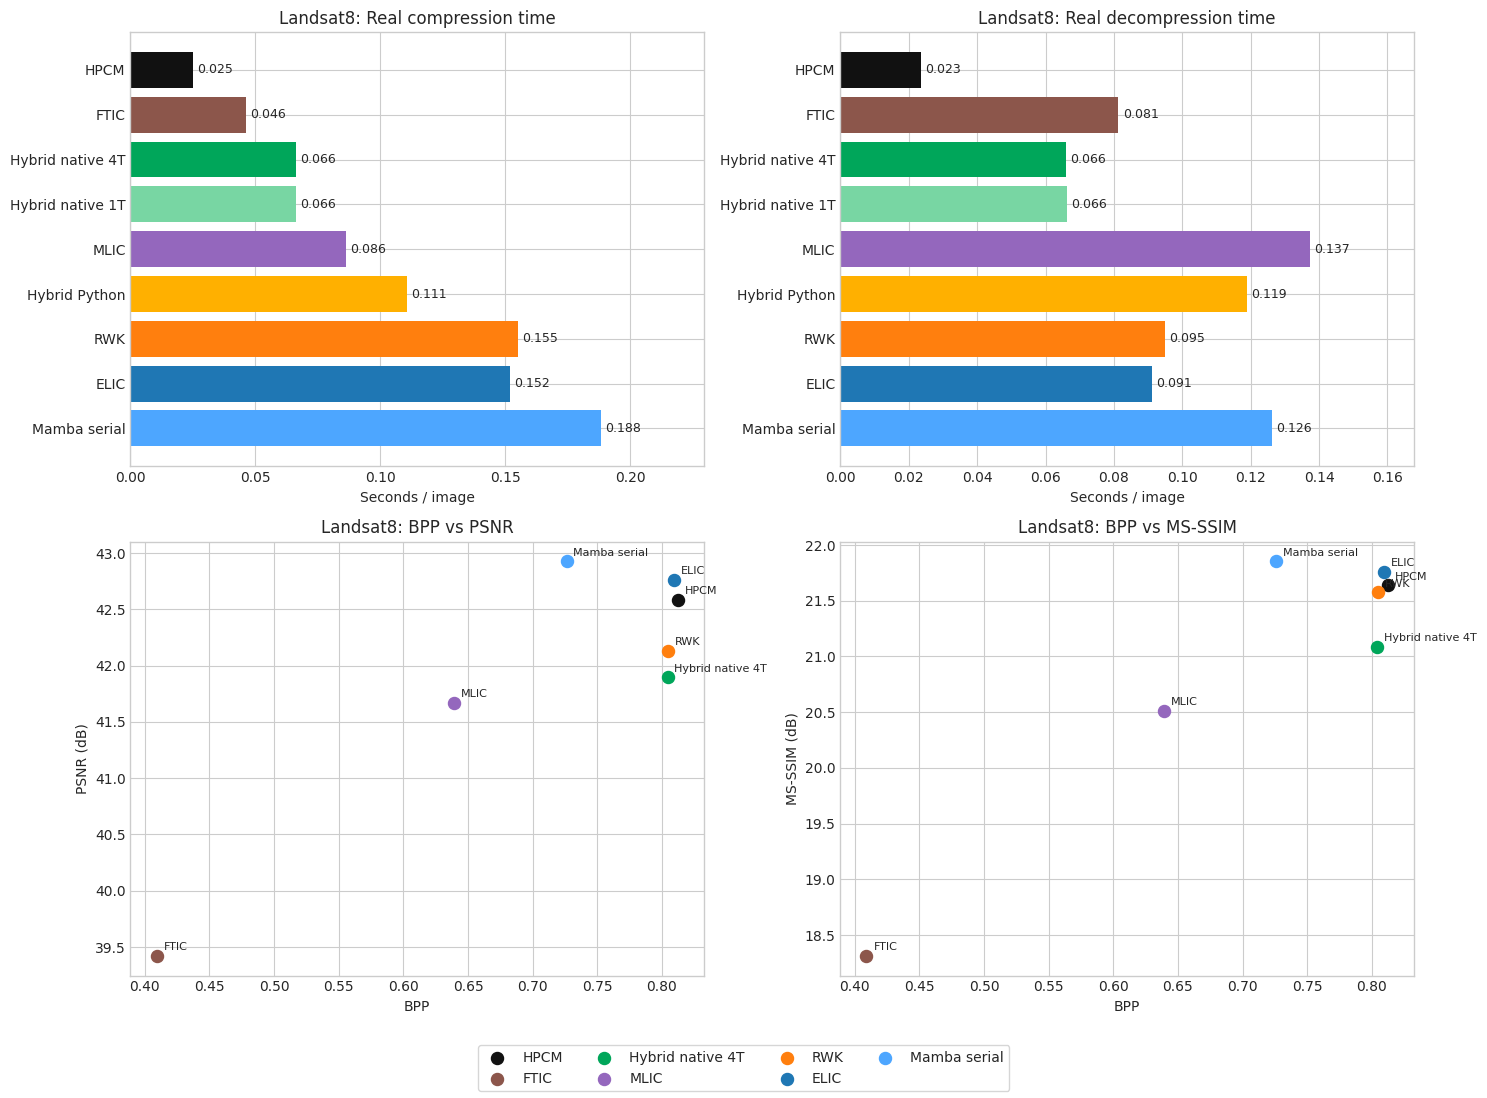

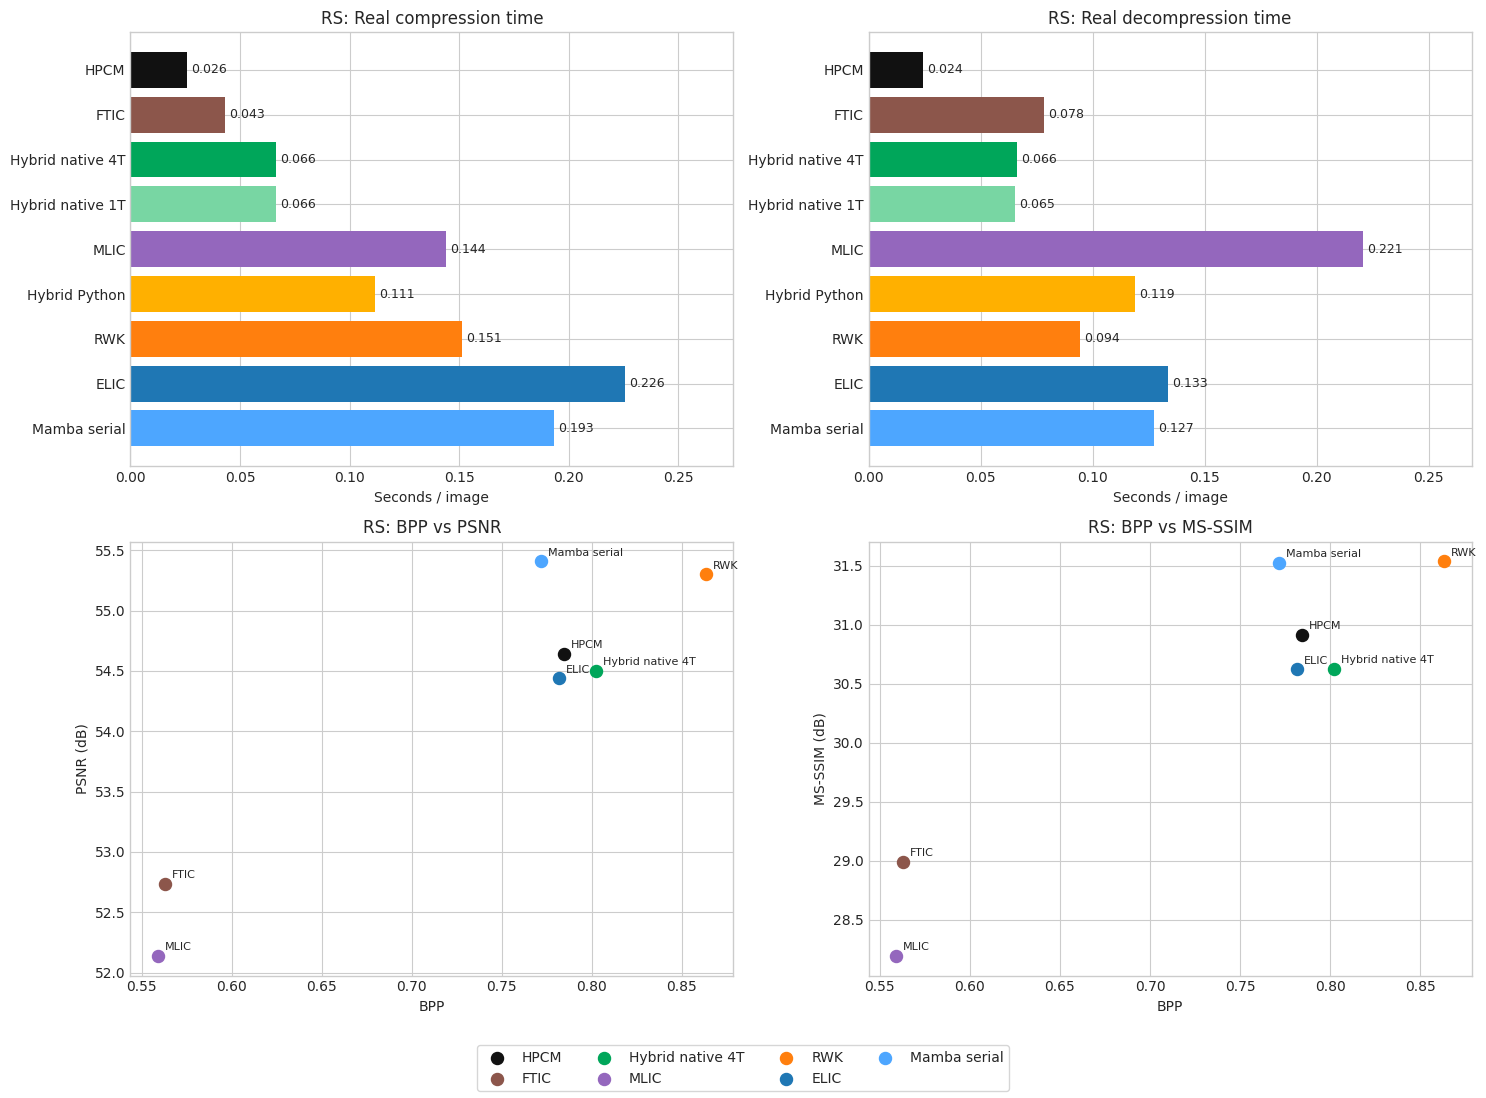

In [3]:
time_order = [
    'HPCM', 'FTIC', 'Hybrid native 4T', 'Hybrid native 1T',
    'MLIC', 'Hybrid Python', 'RWK', 'ELIC', 'Mamba serial'
]
rd_methods = ['HPCM', 'FTIC', 'Hybrid native 4T', 'MLIC', 'RWK', 'ELIC', 'Mamba serial']
colors = {
    'HPCM': '#111111', 'FTIC': '#8c564b', 'Hybrid native 4T': '#00a65a',
    'Hybrid native 1T': '#78d6a3', 'Hybrid Python': '#ffb000',
    'Mamba serial': '#4da6ff', 'MLIC': '#9467bd', 'RWK': '#ff7f0e',
    'ELIC': '#1f77b4',
}

for dataset_name, title in [('landsat8', 'Landsat8'), ('rs', 'RS')]:
    subset = data[data['dataset'] == dataset_name].set_index('display_method')
    ordered = subset.reindex([name for name in time_order if name in subset.index])
    fig, axes = plt.subplots(2, 2, figsize=(15, 11))

    for ax, metric, axis_title in [
        (axes[0, 0], 'compress_mean_s', 'Real compression time'),
        (axes[0, 1], 'decompress_mean_s', 'Real decompression time'),
    ]:
        values = ordered[metric]
        bars = ax.barh(ordered.index, values, color=[colors[name] for name in ordered.index])
        ax.invert_yaxis()
        ax.set_xlabel('Seconds / image')
        ax.set_title(f'{title}: {axis_title}')
        ax.bar_label(bars, labels=[f'{value:.3f}' for value in values], padding=3, fontsize=9)
        ax.set_xlim(0, values.max() * 1.22)

    rd = subset.loc[[name for name in rd_methods if name in subset.index]]
    for ax, metric, ylabel, axis_title in [
        (axes[1, 0], 'psnr', 'PSNR (dB)', 'BPP vs PSNR'),
        (axes[1, 1], 'ms_ssim_db', 'MS-SSIM (dB)', 'BPP vs MS-SSIM'),
    ]:
        for name, row in rd.iterrows():
            ax.scatter(row['bpp'], row[metric], s=75, color=colors[name], label=name)
            ax.annotate(name, (row['bpp'], row[metric]), xytext=(5, 4),
                        textcoords='offset points', fontsize=8)
        ax.set_xlabel('BPP')
        ax.set_ylabel(ylabel)
        ax.set_title(f'{title}: {axis_title}')

    handles, legend_labels = axes[1, 1].get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc='lower center', ncol=4, frameon=True)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    plt.show()

## Parallel implementation speedups

,4T encode speedup vs Python,4T decode speedup vs Python,4T encode speedup vs Mamba,4T decode speedup vs Mamba,4T encode speedup vs native 1T,4T decode speedup vs native 1T
dataset,,,,,,
landsat8,1.674x,1.799x,2.845x,1.912x,1.005x,1.002x
rs,1.680x,1.799x,2.915x,1.930x,1.001x,0.990x


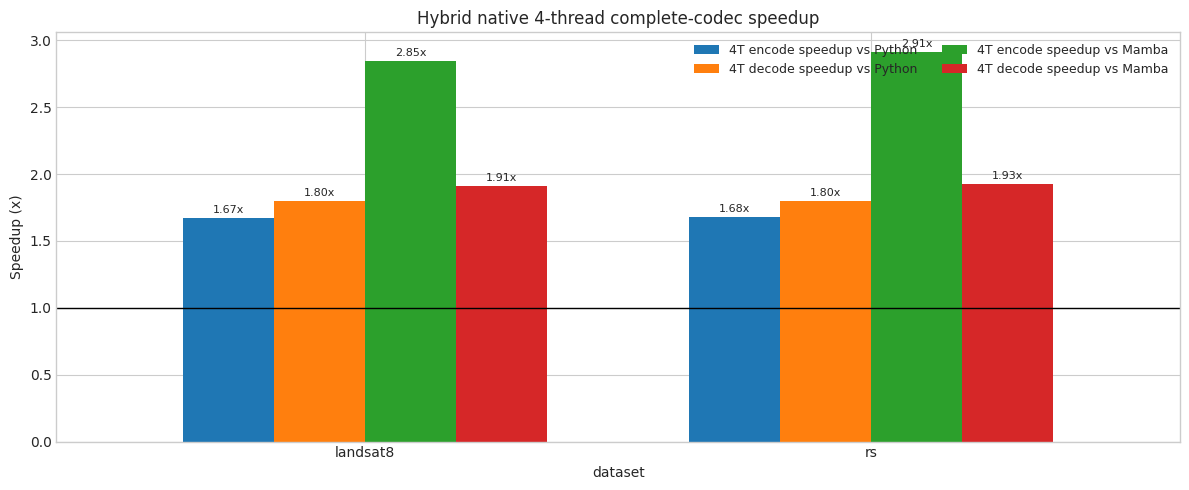

In [4]:
speed_rows = []
for dataset_name in ['landsat8', 'rs']:
    rows = data[data['dataset'] == dataset_name].set_index('method')
    final = rows.loc['hybrid_native_4w']
    python_serial = rows.loc['hybrid_python_serial']
    native_one = rows.loc['hybrid_native_1w']
    mamba = rows.loc['mamba_serial']
    speed_rows.append({
        'dataset': dataset_name,
        '4T encode speedup vs Python': python_serial.compress_mean_s / final.compress_mean_s,
        '4T decode speedup vs Python': python_serial.decompress_mean_s / final.decompress_mean_s,
        '4T encode speedup vs Mamba': mamba.compress_mean_s / final.compress_mean_s,
        '4T decode speedup vs Mamba': mamba.decompress_mean_s / final.decompress_mean_s,
        '4T encode speedup vs native 1T': native_one.compress_mean_s / final.compress_mean_s,
        '4T decode speedup vs native 1T': native_one.decompress_mean_s / final.decompress_mean_s,
    })
speedups = pd.DataFrame(speed_rows).set_index('dataset')
display(speedups.style.format('{:.3f}x'))

plot_columns = [
    '4T encode speedup vs Python', '4T decode speedup vs Python',
    '4T encode speedup vs Mamba', '4T decode speedup vs Mamba',
]
ax = speedups[plot_columns].plot(kind='bar', figsize=(12, 5), rot=0, width=0.72)
ax.axhline(1.0, color='black', linewidth=1)
ax.set_ylabel('Speedup (x)')
ax.set_title('Hybrid native 4-thread complete-codec speedup')
ax.legend(ncol=2, fontsize=9)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2fx', padding=2, fontsize=8)
plt.tight_layout()
plt.show()

## Interpretation

- `Hybrid native 4T` 保持与 Python 串行版本完全相同的 BPP、PSNR、MS-SSIM，并通过了 latent 一致性检查。
- 原生后端相对 Python/CompressAI 串行路径显著降低完整编码和解码时间。
- 原生 4 线程与原生 1 线程接近，说明 rANS 算术已不再是完整流程的主要瓶颈；剩余时间主要来自神经网络、上下文预测和数据搬运。
- HPCM 仍是当前最快基线。最终论文应在完整测试集上重复计时，而当前 5 张图结果适合作为实现验证和瓶颈分析。